# DM-2 — Exercice 1 : Classification MNIST avec AdaBoost

## Objectif

L'objectif est d'étudier les performances de l'algorithme AdaBoost sur deux problèmes de classification binaire du jeu MNIST :

- Chiffres 3 contre 8 ;
- Chiffres 0 à 4 contre chiffres 5 à 9.

Nous comparons quatre classifieurs de base :

- Decision stump (profondeur 1) ;
- Arbre de décision (profondeur 3) ;
- Arbre de décision (profondeur 8) ;
- Perceptron.

Pour chaque classifieur, nous testons 10, 50 et 100 estimateurs.

Les performances sont évaluées à l'aide des matrices de confusion, de l'accuracy, de la précision, du rappel et du score F1.

Aucune réduction de dimension par ACP n'est utilisée.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import Perceptron
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.base import clone
import joblib
import time

print("Bibliothèques importées avec succès.")


/home/lucca/00_projetos/DM2_Machine_Learning/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Bibliothèques importées avec succès.


In [2]:

# Définition des répertoires
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = RESULTS_DIR / "models"

RESULTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

# Chargement des deux problèmes binaires
data_38 = np.load(DATA_DIR / "mnist_3_vs_8.npz")
data_group = np.load(DATA_DIR / "mnist_0_4_vs_5_9.npz")

datasets = {
    "3_vs_8": {
        "X_train": data_38["X_train"],
        "X_test": data_38["X_test"],
        "y_train": data_38["y_train"],
        "y_test": data_38["y_test"],
        "labels": [3, 8]
    },
    "0_4_vs_5_9": {
        "X_train": data_group["X_train"],
        "X_test": data_group["X_test"],
        "y_train": data_group["y_train"],
        "y_test": data_group["y_test"],
        "labels": [0, 1]
    }
}

for name, data in datasets.items():
    print(f"{name} : {data['X_train'].shape[0]} images d'entraînement")


3_vs_8 : 11172 images d'entraînement
0_4_vs_5_9 : 56000 images d'entraînement


In [3]:

# Classifieurs de base
classifiers = {
    "stump": DecisionTreeClassifier(max_depth=1, random_state=42),
    "tree_depth_3": DecisionTreeClassifier(max_depth=3, random_state=42),
    "tree_depth_8": DecisionTreeClassifier(max_depth=8, random_state=42),
    "perceptron": Perceptron(max_iter=1000, tol=1e-3, random_state=42)
}

# Nombre d'estimateurs AdaBoost
n_estimators_values = [10, 50, 100]

print("Classifieurs :", list(classifiers.keys()))
print("Nombre d'estimateurs :", n_estimators_values)
print("Nombre total de configurations :", len(datasets) * len(classifiers) * len(n_estimators_values))


Classifieurs : ['stump', 'tree_depth_3', 'tree_depth_8', 'perceptron']
Nombre d'estimateurs : [10, 50, 100]
Nombre total de configurations : 24


Temps d'entraînement : 1.55 secondes
Accuracy : 0.9052


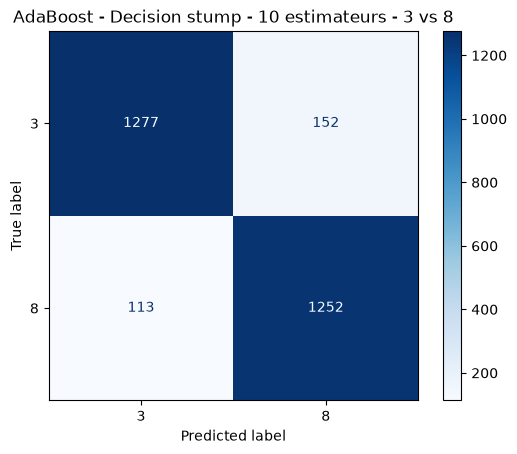

In [4]:

# Premier test : AdaBoost avec decision stumps
data = datasets["3_vs_8"]

model = AdaBoostClassifier(
    estimator=clone(classifiers["stump"]),
    n_estimators=10,
    random_state=42
)

start_time = time.time()

model.fit(data["X_train"], data["y_train"])

training_time = time.time() - start_time

y_pred = model.predict(data["X_test"])

print(f"Temps d'entraînement : {training_time:.2f} secondes")
print(f"Accuracy : {accuracy_score(data['y_test'], y_pred):.4f}")

cm = confusion_matrix(
    data["y_test"],
    y_pred,
    labels=data["labels"]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data["labels"]
).plot(cmap="Blues")

plt.title("AdaBoost - Decision stump - 10 estimateurs - 3 vs 8")
plt.show()



### 1.1 Vérification du perceptron

Avant de lancer l'ensemble des exmpériences, nous vérifions que le perceptron peut être utilisé comme classifieur de base dans AdaBoost avec la version installée de scikit-learn.

In [6]:

import sklearn

print("Version de scikit-learn :", sklearn.__version__)

# Test sur un sous-ensemble pour vérifier la compatibilité
data = datasets["3_vs_8"]

test_model = AdaBoostClassifier(
    estimator=clone(classifiers["perceptron"]),
    n_estimators=3,
    random_state=42
)

try:
    test_model.fit(
        data["X_train"][:1000],
        data["y_train"][:1000]
    )
    print("Test du perceptron réussi.")
    print("Estimateurs entraînés :", len(test_model.estimators_))
except Exception as e:
    print("Problème détecté :", type(e).__name__, str(e))


Version de scikit-learn : 1.9.1
Test du perceptron réussi.
Estimateurs entraînés : 3


### 1.2 Comparaison des configurations AdaBoost

Nous réalisons une étude expérimentale en faisant varier trois paramètres :

- Le classifieur de base : stump, arbre de profondeur 3, arbre de profondeur 8 et perceptron ;
- Le nombre d'estimateurs : 10, 50 et 100 ;
- Le problème de classification : 3 contre 8 et 0–4 contre 5–9.

Pour chaque configuration, nous mesurons le temps d'entraînement, l'accuracy, la précision, le rappel et le score F1. Nous conservons également la matrice de confusion.

Une barre de progression permet de suivre l'avancement des expériences.

In [7]:

from itertools import product

# Toutes les combinaisons expérimentales
configurations = list(product(
    datasets.keys(),
    classifiers.keys(),
    n_estimators_values
))

resultats = []
matrices_confusion = {}

# Barre de progression globale
with tqdm(configurations, desc="Expériences AdaBoost", unit="modèle") as pbar:

    for dataset_name, classifier_name, n_estimators in pbar:

        pbar.set_postfix(
            dataset=dataset_name,
            modele=classifier_name,
            N=n_estimators
        )

        data = datasets[dataset_name]

        # Création du modèle
        model = AdaBoostClassifier(
            estimator=clone(classifiers[classifier_name]),
            n_estimators=n_estimators,
            random_state=42
        )

        debut = time.perf_counter()

        try:
            # Entraînement
            model.fit(data["X_train"], data["y_train"])

            duree = time.perf_counter() - debut

            # Prédictions
            y_pred = model.predict(data["X_test"])

            # Métriques
            accuracy = accuracy_score(data["y_test"], y_pred)
            precision = precision_score(
                data["y_test"], y_pred,
                pos_label=data["labels"][1],
                zero_division=0
            )
            rappel = recall_score(
                data["y_test"], y_pred,
                pos_label=data["labels"][1],
                zero_division=0
            )
            f1 = f1_score(
                data["y_test"], y_pred,
                pos_label=data["labels"][1],
                zero_division=0
            )

            # Matrice de confusion
            cm = confusion_matrix(
                data["y_test"],
                y_pred,
                labels=data["labels"]
            )

            cle = f"{dataset_name}_{classifier_name}_{n_estimators}"
            matrices_confusion[cle] = cm

            resultats.append({
                "dataset": dataset_name,
                "classifieur": classifier_name,
                "n_estimators": n_estimators,
                "n_estimators_effectifs": len(model.estimators_),
                "accuracy": accuracy,
                "precision": precision,
                "recall": rappel,
                "f1_score": f1,
                "temps_secondes": duree,
                "statut": "OK"
            })

            # Conservation des modèles avec stumps
            # pour les cartes de saillance (exercice 2)
            if classifier_name == "stump":
                joblib.dump(
                    model,
                    MODELS_DIR / f"{cle}.joblib"
                )

        except Exception as e:
            resultats.append({
                "dataset": dataset_name,
                "classifieur": classifier_name,
                "n_estimators": n_estimators,
                "statut": f"ERREUR : {type(e).__name__}: {e}"
            })

            tqdm.write(f"Erreur pour {dataset_name}, "
                       f"{classifier_name}, N={n_estimators} : {e}")

        # Sauvegarde après chaque configuration
        df_resultats = pd.DataFrame(resultats)
        df_resultats.to_csv(
            RESULTS_DIR / "resultats_adaboost.csv",
            index=False
        )

print("\nExpériences terminées !")
print("Configurations exécutées :", len(resultats))
print("Configurations réussies :",
      sum(r["statut"] == "OK" for r in resultats))

display(df_resultats)


Expériences AdaBoost: 100%|██████████| 24/24 [28:00<00:00, 70.02s/modèle, N=100, dataset=0_4_vs_5_9, modele=perceptron]


Expériences terminées !
Configurations exécutées : 24
Configurations réussies : 24


,dataset,classifieur,n_estimators,n_estimators_effectifs,accuracy,precision,recall,f1_score,temps_secondes,statut
0,3_vs_8,stump,10,10,0.905154,0.891738,0.917216,0.904298,1.478340,OK
1,3_vs_8,stump,50,50,0.945240,0.944934,0.942857,0.943894,7.412176,OK
2,3_vs_8,stump,100,100,0.955261,0.953216,0.955311,0.954263,14.281858,OK
3,3_vs_8,tree_depth_3,10,10,0.963851,0.955331,0.971429,0.963313,3.884276,OK
4,3_vs_8,tree_depth_3,50,50,0.987473,0.986823,0.987546,0.987184,19.377852,OK
5,3_vs_8,tree_depth_3,100,100,0.990694,0.991918,0.989011,0.990462,38.826836,OK
6,3_vs_8,tree_depth_8,10,10,0.986042,0.984649,0.986813,0.985730,9.350699,OK
7,3_vs_8,tree_depth_8,50,50,0.992126,0.991222,0.992674,0.991947,46.014267,OK
8,3_vs_8,tree_depth_8,100,100,0.992842,0.991953,0.993407,0.992679,92.009898,OK
9,3_vs_8,perceptron,10,8,0.949893,0.932251,0.967766,0.949676,1.025752,OK


### 1.3 Analyse comparative des performances

Nous comparons l'accuracy des différents classifieurs en fonction du nombre d'estimateurs et du problème de classification.

Cette analyse permet d'étudier l'influence de la complexité des classifieurs de base et du nombre d'étapes de boosting sur les performances.

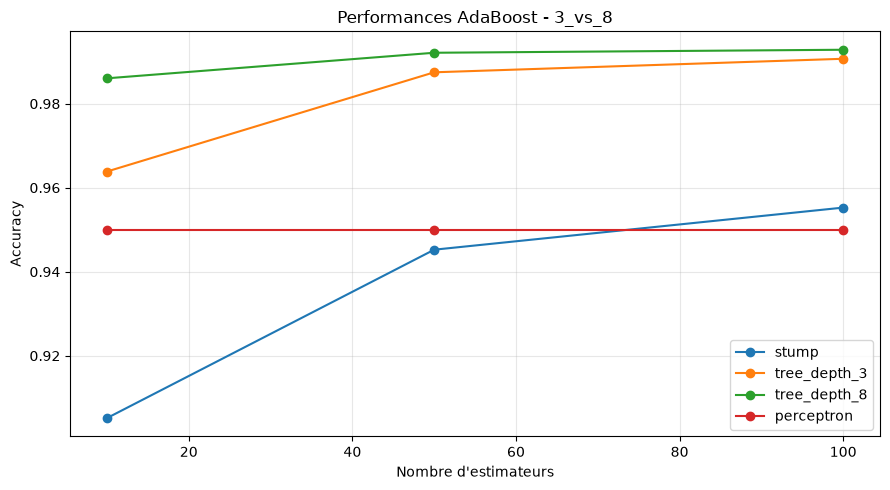

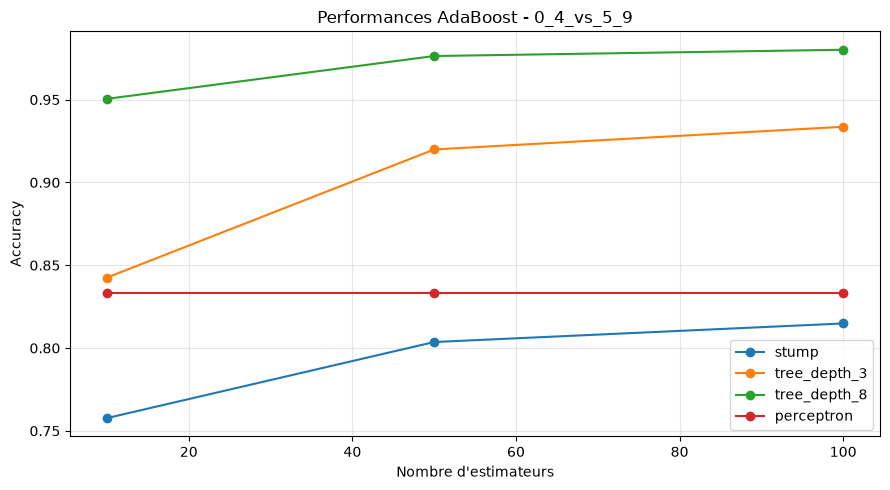

In [8]:

# Sélection des expériences réussies
df_ok = df_resultats[df_resultats["statut"] == "OK"].copy()

for dataset_name in datasets.keys():

    subset = df_ok[df_ok["dataset"] == dataset_name]

    plt.figure(figsize=(9, 5))

    for classifier_name in classifiers.keys():

        valeurs = subset[
            subset["classifieur"] == classifier_name
        ].sort_values("n_estimators")

        plt.plot(
            valeurs["n_estimators"],
            valeurs["accuracy"],
            marker="o",
            label=classifier_name
        )

    plt.xlabel("Nombre d'estimateurs")
    plt.ylabel("Accuracy")
    plt.title(f"Performances AdaBoost - {dataset_name}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR / f"accuracy_{dataset_name}.png",
        dpi=150
    )

    plt.show()


### 1.4 Matrices de confusion

Pour chaque combinaison de paramètres, nous présentons la matrice de confusion obtenue sur l'ensemble de test.

Ces matrices permettent d'identifier les erreurs de classification et de comparer les performances des différents modèles.

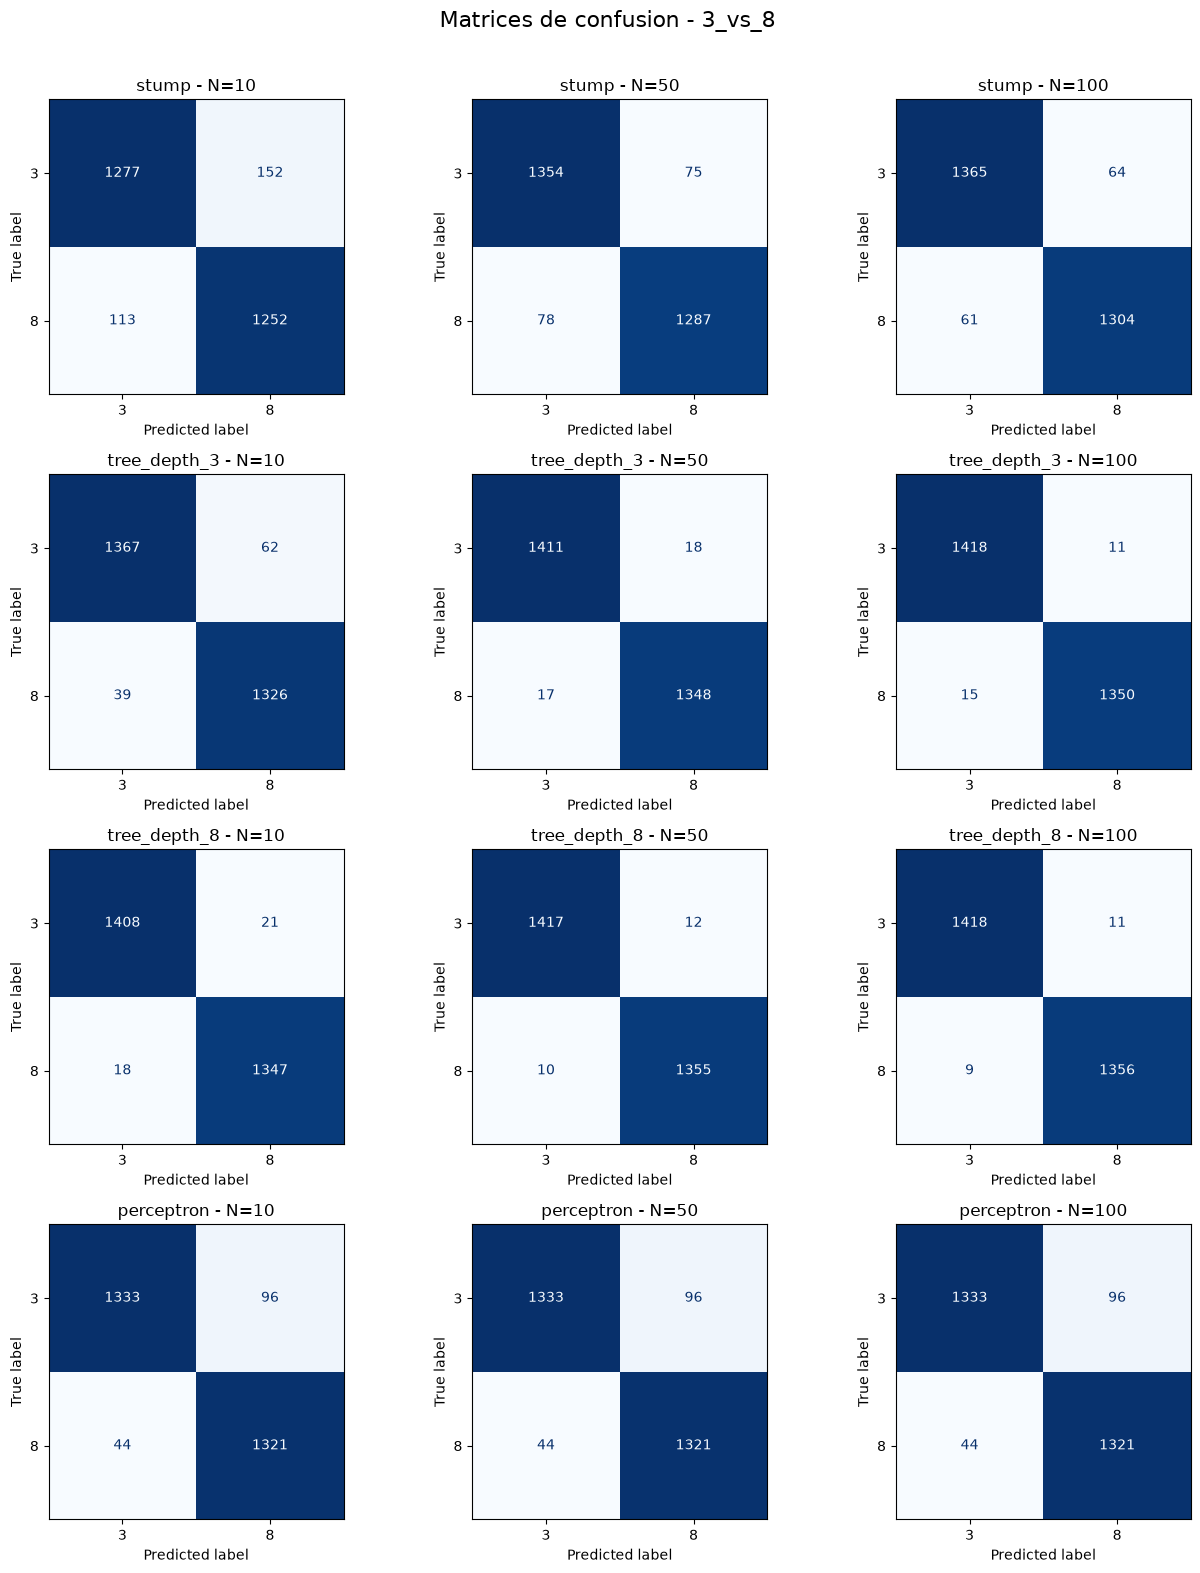

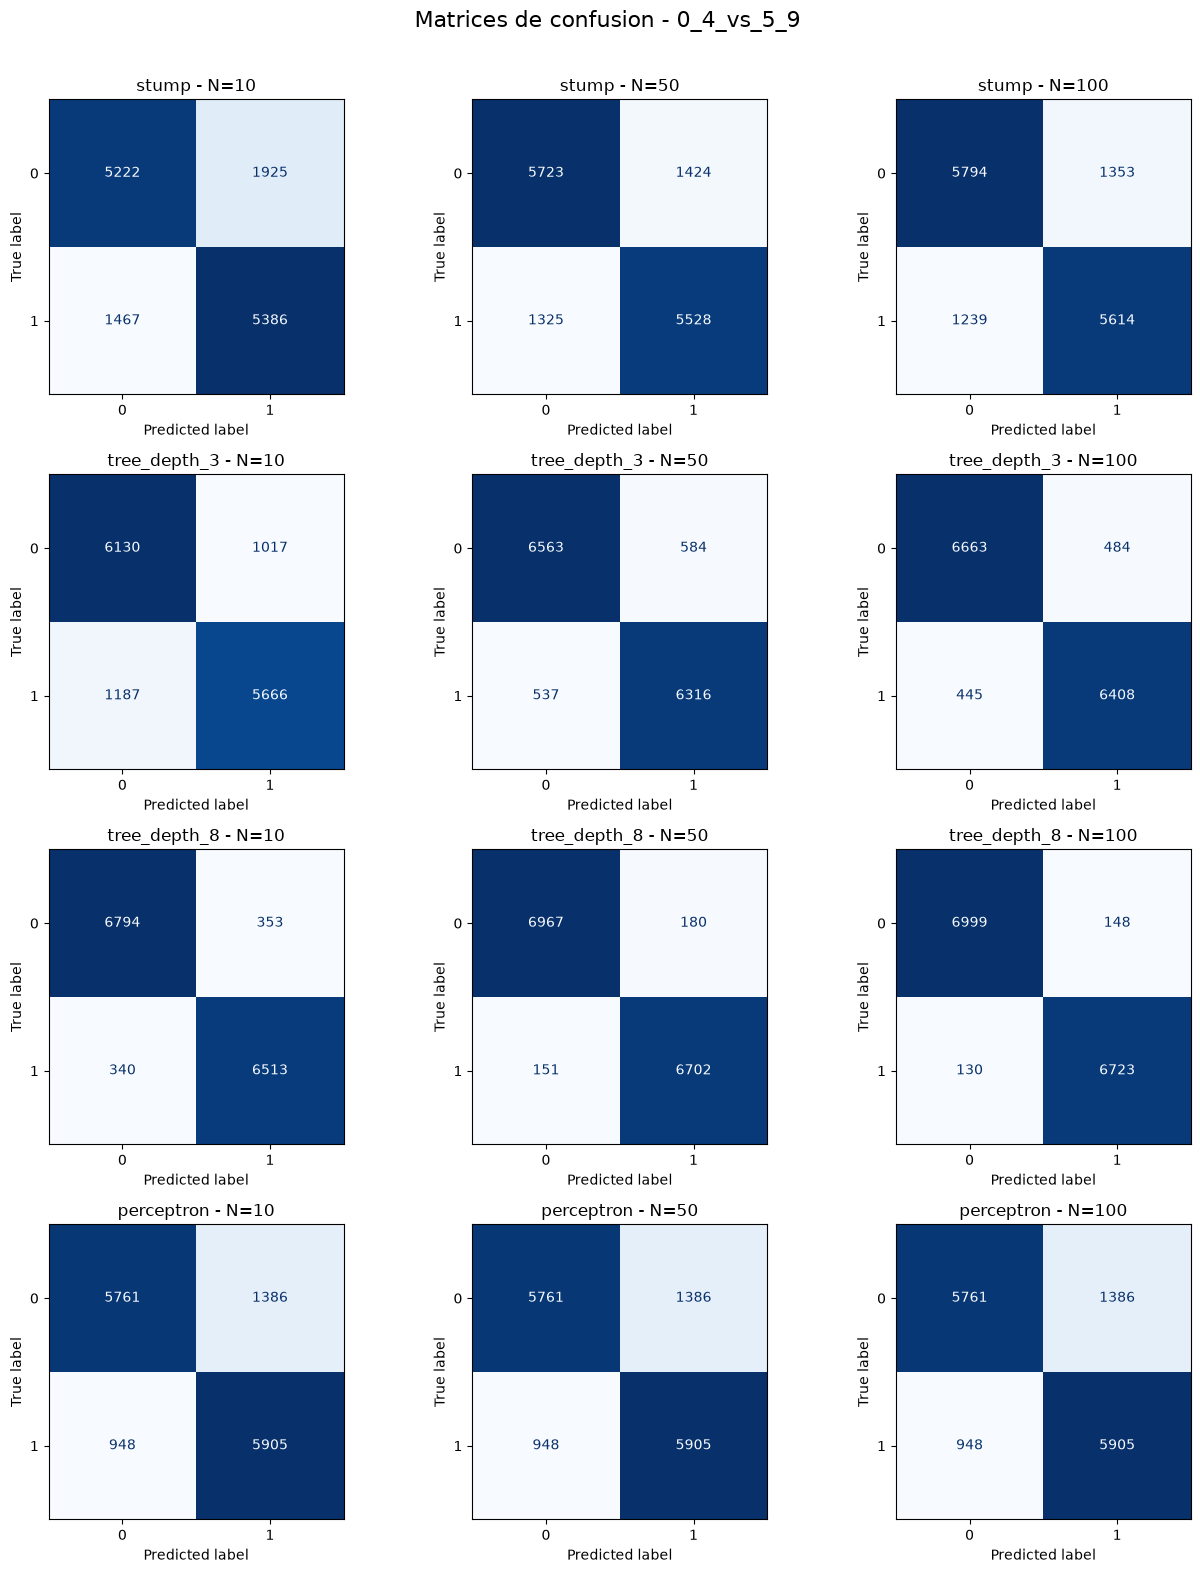

In [9]:

# Visualisation de toutes les matrices de confusion

for dataset_name, data in datasets.items():

    fig, axes = plt.subplots(4, 3, figsize=(13, 16))

    for i, classifier_name in enumerate(classifiers.keys()):
        for j, n_estimators in enumerate(n_estimators_values):

            ax = axes[i, j]
            cle = f"{dataset_name}_{classifier_name}_{n_estimators}"

            if cle in matrices_confusion:
                cm = matrices_confusion[cle]

                disp = ConfusionMatrixDisplay(
                    confusion_matrix=cm,
                    display_labels=data["labels"]
                )

                disp.plot(
                    ax=ax,
                    cmap="Blues",
                    colorbar=False,
                    values_format="d"
                )

                ax.set_title(
                    f"{classifier_name} - N={n_estimators}"
                )
            else:
                ax.text(
                    0.5, 0.5,
                    "Résultat indisponible",
                    ha="center", va="center"
                )
                ax.axis("off")

    fig.suptitle(
        f"Matrices de confusion - {dataset_name}",
        fontsize=16
    )

    plt.tight_layout(rect=[0, 0, 1, 0.97])

    plt.savefig(
        RESULTS_DIR / f"confusion_matrices_{dataset_name}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()


### 1.5 Identification des configurations les plus favorables et défavorables

Nous identifions les configurations présentant les meilleures et les moins bonnes performances pour chaque problème de classification.

Nous examinons également le nombre effectif d'estimateurs entraînés, car AdaBoost peut interrompre l'apprentissage avant le nombre maximal demandé.

In [10]:

# Vérification des expériences
print("Nombre d'expériences réussies :", len(df_ok))
print("Nombre d'expériences prévues :", len(configurations))

for dataset_name in datasets.keys():

    subset = df_ok[
        df_ok["dataset"] == dataset_name
    ].copy()

    if subset.empty:
        print(f"\nAucun résultat disponible pour {dataset_name}")
        continue

    meilleur = subset.loc[subset["accuracy"].idxmax()]
    moins_bon = subset.loc[subset["accuracy"].idxmin()]

    print(f"\n===== {dataset_name} =====")

    print("\nMeilleure configuration :")
    print(meilleur[
        ["classifieur", "n_estimators",
         "n_estimators_effectifs", "accuracy", "f1_score"]
    ])

    print("\nConfiguration la moins performante :")
    print(moins_bon[
        ["classifieur", "n_estimators",
         "n_estimators_effectifs", "accuracy", "f1_score"]
    ])

# Tableau comparatif général
colonnes = [
    "dataset", "classifieur", "n_estimators",
    "n_estimators_effectifs", "accuracy",
    "precision", "recall", "f1_score", "temps_secondes"
]

display(
    df_ok[colonnes].sort_values(
        ["dataset", "accuracy"],
        ascending=[True, False]
    ).round(4)
)


Nombre d'expériences réussies : 24
Nombre d'expériences prévues : 24

===== 3_vs_8 =====

Meilleure configuration :
classifieur               tree_depth_8
n_estimators                       100
n_estimators_effectifs             100
accuracy                      0.992842
f1_score                      0.992679
Name: 8, dtype: object

Configuration la moins performante :
classifieur                  stump
n_estimators                    10
n_estimators_effectifs          10
accuracy                  0.905154
f1_score                  0.904298
Name: 0, dtype: object

===== 0_4_vs_5_9 =====

Meilleure configuration :
classifieur               tree_depth_8
n_estimators                       100
n_estimators_effectifs             100
accuracy                      0.980143
f1_score                      0.979744
Name: 20, dtype: object

Configuration la moins performante :
classifieur                  stump
n_estimators                    10
n_estimators_effectifs          10
accuracy         

,dataset,classifieur,n_estimators,n_estimators_effectifs,accuracy,precision,recall,f1_score,temps_secondes
20,0_4_vs_5_9,tree_depth_8,100,100,0.9801,0.9785,0.9810,0.9797,523.7850
19,0_4_vs_5_9,tree_depth_8,50,50,0.9764,0.9738,0.9780,0.9759,269.4572
18,0_4_vs_5_9,tree_depth_8,10,10,0.9505,0.9486,0.9504,0.9495,55.0453
17,0_4_vs_5_9,tree_depth_3,100,100,0.9336,0.9298,0.9351,0.9324,220.3592
16,0_4_vs_5_9,tree_depth_3,50,50,0.9199,0.9154,0.9216,0.9185,108.5166
15,0_4_vs_5_9,tree_depth_3,10,10,0.8426,0.8478,0.8268,0.8372,21.9204
21,0_4_vs_5_9,perceptron,10,7,0.8333,0.8099,0.8617,0.8350,3.2120
22,0_4_vs_5_9,perceptron,50,7,0.8333,0.8099,0.8617,0.8350,3.2420
23,0_4_vs_5_9,perceptron,100,7,0.8333,0.8099,0.8617,0.8350,3.2841
14,0_4_vs_5_9,stump,100,100,0.8149,0.8058,0.8192,0.8124,82.2335
